# 02 · Artigo 1 — problema de *revamp* (Souza et al., 2014)

Reprodução da Figura 5 e das Tabelas XII-XVI: a rede ótima do problema *grassroots* é
expandida com os trocadores E-105B (em paralelo com E-105, modelado como E-105A/B) e E-106,
alimentado pelas tubulações novas 29 e 30. As tubulações divididas da solução anterior
(7, 8, 13, 14 e 16) tornaram-se arestas separadas (24-28). A bomba existente (curva 1) e os
tubos existentes podem ser mantidos a custo zero; válvulas (perdas `y_h`) entram como
variáveis de decisão (Eqs. 34-36).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwnet import load_case, run_design_study
from cwnet.reporting import plots, tables

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CASES = Path("../cases")

In [2]:
case = load_case(CASES / "paper1_revamp.yaml")
print(case.name); print(case.description)

Paper 1 - revamp of the cooling water network
27 nodes, 31 edges: existing pump, 22 existing + 2 new pipe sections, 6 heat exchangers


## Figura 5 — digrafo da rede revampeada (tubos existentes tracejados)

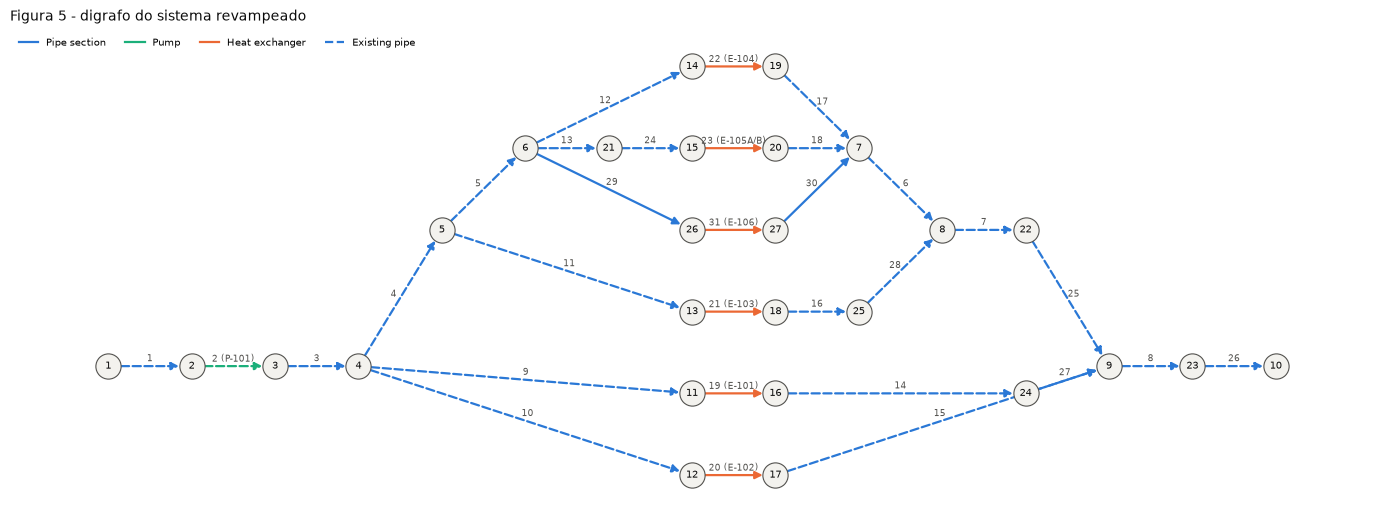

In [3]:
ax = plots.plot_digraph(case, title="Figura 5 - digrafo do sistema revampeado")

## Tabela XII — comprimentos das tubulações

In [4]:
display(tables.pipe_lengths_table(case))

,Pipe section,Length (m)
0,14,5.08
1,13,5.62
2,16,8.82
3,1,10.00
4,28,16.18
5,24,19.38
6,27,19.93
7,"9, 10, 11, 15, 18, 29, 30",25.00
8,26,38.00
9,7,39.90


## Tabela XIII — vazões mássicas após a expansão

In [5]:
study = run_design_study(case)
display(tables.mass_flow_table(study))

,Edge,Mass flow rate (kg/s)
0,"1, 2, 3, 8, 26",109.2
1,"4, 7, 25",73.0
2,"5, 6",37.4
3,"11, 16, 21, 28",35.6
4,"10, 15, 20",28.7
5,"12, 17, 22, 29, 30, 31",15.6
6,"9, 14, 19, 27",7.5
7,"13, 18, 23, 24",6.2


## Tabela XIV — diâmetros antes do revamp, projeto tradicional e projeto otimizado

A coluna *Optimization* corresponde ao LP com a bomba 3 (a mais barata, Tabela XVI). A
solução indica a válvula do E-101 com **3.763 m** de perda de carga e zero nos demais,
exatamente como no artigo. Como no caso *grassroots*, o LP é degenerado: trechos de
diâmetro podem trocar entre tubulações em série (por exemplo 10 e 15) sem alterar o custo.

In [6]:
PUBLISHED_XIV_OPT = {1: "10", 3: "12", 4: "10", 5: "8", 6: "6/8 (0.041/0.959)", 7: "10/8 (0.355/0.645)", 8: "10",
    9: "3 1/2", 10: "6/8 (0.272/0.728)", 11: "8", 12: "6", 13: "3", 14: "3 1/2", 15: "6", 16: "6", 17: "6", 18: "3",
    24: "3/2 (0.388/0.612)", 25: "10", 26: "12", 27: "4", 28: "8", 29: "5", 30: "5/4 (0.063/0.937)"}
PUBLISHED_XIV_TRAD = {1: "12", 3: "12", 4: "10", 5: "8", 6: "8", 7: "10", 8: "12", 9: "4", 10: "6", 11: "8", 12: "6",
    13: "3", 14: "4", 15: "6", 16: "8", 17: "6", 18: "3", 24: "3", 25: "10", 26: "12", 27: "4", 28: "8", 29: "5", 30: "5"}
tbl = tables.design_comparison_table(study, traditional="edgar_himmelblau")
tbl["Published traditional"] = [PUBLISHED_XIV_TRAD[e] for e in tbl["Edge"]]
tbl["Published optimization"] = [PUBLISHED_XIV_OPT[e] for e in tbl["Edge"]]
display(tbl)
display(tables.valve_table(study.best, case))

,Edge,Diameter before revamp (in),Traditional diameter (in),Optimization diameter (in),Optimization length fraction,Published traditional,Published optimization
0,1,10,12,10,1.000,12,10
1,3,12,12,12,1.000,12,12
2,4,8,10,10,1.000,10,10
3,5,6,8,8,1.000,8,8
4,6,6,8,6/8,0.041/0.959,8,6/8 (0.041/0.959)
5,7,8,10,8/10,0.645/0.355,10,10/8 (0.355/0.645)
6,8,10,12,10,1.000,12,10
7,9,3 1/2,3 1/2,3 1/2,1.000,4,3 1/2
8,10,6,6,6,1.000,6,6/8 (0.272/0.728)
9,11,8,8,8,1.000,8,8


,Heat exchanger,revamp (m)
0,E-101,3.763
1,E-102,0.000
2,E-103,0.000
3,E-104,0.000
4,E-105A/B,0.000
5,E-106,0.000


### Sobre a coluna tradicional publicada

Com a vazão nova do E-101 (7.5 kg/s) o head mínimo requerido é **14.36 m** (o artigo cita
14.4 m) e a **bomba 3** (15.57 m a 109.2 kg/s) já é suficiente; as tubulações 9 e 14 ficam
em 3 1/2". A tabela publicada, porém, mostra 4" para 9 e 14 e a **bomba 4** — resultado que
se obtém dimensionando as linhas do E-101 com a vazão antiga, 11.8 kg/s (vazão total
113.5 kg/s). O relatório Scilab original reaproveitou um ficheiro de resultados do projeto
tradicional gerado com essa versão anterior dos dados (a v2.2 do código não recalcula o
tradicional). As Tabelas XIV-XVI "como publicadas" são reproduzidas abaixo com essa
hipótese explícita.

In [7]:
from cwnet.design.evaluate import evaluate_design
from cwnet.design.traditional import traditional_design
from cwnet.hydraulics.headloss import build_hydraulic_tables
from cwnet.topology.massbalance import solve_all_scenarios

alt = case.model_copy(deep=True)
alt.scenarios[0].flows["E-101"] = 11.8
bal_alt = solve_all_scenarios(alt, study.topology)
hyd_alt = build_hydraulic_tables(alt, bal_alt)
trad_pub_design = traditional_design(alt, study.topology, hyd_alt, bal_alt, "edgar_himmelblau")
trad_pub = evaluate_design(case, study.topology, study.balances, trad_pub_design, study.cost_matrix,
                           label="Traditional (as published: E-101 sized at 11.8 kg/s)")
print("bomba:", trad_pub_design.pump_curve, "| head requerido: %.2f m" % trad_pub_design.required_pump_head)
print("diâmetros 9, 14, 27:", [trad_pub_design.pipes[e].describe(case)[0] for e in (9, 14, 27)])

bomba: Curve 4 | head requerido: 14.54 m
diâmetros 9, 14, 27: ['4', '4', '4']


## Tabela XV — comportamento da rede com o projeto tradicional (como publicado)

In [8]:
PUBLISHED_XV = {"E-101": (7.5, 12.0), "E-102": (28.7, 28.0), "E-103": (35.6, 36.5), "E-104": (15.6, 15.5),
                "E-105A/B": (6.2, 8.3), "E-106": (15.6, 16.8)}
tab = tables.network_behaviour_table(trad_pub)
tab["Published simulated flow (kg/s)"] = [PUBLISHED_XV[t][1] if t in PUBLISHED_XV else 117.1 for t in tab["Heat exchanger"]]
display(tab)

,Heat exchanger,Design flow (kg/s),Simulated flow (kg/s),Design hot outlet (degC),Simulated hot outlet (degC),Simulated cold outlet (degC),Published simulated flow (kg/s)
0,E-101,7.5,12.03,65.0,64.1,40.3,12.0
1,E-102,28.7,28.04,80.0,79.3,40.3,28.0
2,E-103,35.6,36.51,40.0,40.0,39.8,36.5
3,E-104,15.6,15.55,41.0,41.1,40.0,15.5
4,E-105A/B,6.2,8.32,41.0,39.5,38.3,8.3
5,E-106,15.6,16.79,41.0,40.8,39.5,16.8
6,Total,109.2,117.24,NaN,NaN,NaN,117.1


## Tabela XVI — comparação econômica

Os quatro LPs reproduzem a tabela publicada (bomba 3 é a melhor, 12.1 % mais barata que o
tradicional publicado). A linha *Traditional (consistent)* usa a vazão nova do E-101.

In [9]:
PUBLISHED_XVI = {"Traditional": (37378, 24193, 3409, 9776), "Proposed / Curve 1": (43746, 18265, 0, 25481),
    "Proposed / Curve 2": (34622, 21918, 3209, 9495), "Proposed / Curve 3": (32857, 24353, 3312, 5192),
    "Proposed / Curve 4": (33142, 26789, 3409, 2944)}
rows = []
def row(label, ev, pub):
    c = ev.costs
    return {"Methodology / case": label, "Pump": ev.design.pump_curve, "Total (USD/y)": round(c.total),
            "Operational (USD/y)": round(c.operating), "Pump (USD/y)": round(c.pump_capital_annualized),
            "Pipe (USD)": round(c.pipe_capital), "Published total": pub[0], "Published operational": pub[1],
            "Published pump": pub[2], "Published pipe": pub[3]}
rows.append(row("Traditional (as published)", trad_pub, PUBLISHED_XVI["Traditional"]))
rows.append(row("Traditional (consistent, E-101 = 7.5 kg/s)", study.traditional["edgar_himmelblau"], (None,)*4))
for ev in study.lp:
    rows.append(row(ev.label, ev, PUBLISHED_XVI[ev.label]))
display(pd.DataFrame(rows))
print("redução vs tradicional publicado: %.1f %% (artigo: 12.1 %%)" % (100 * (1 - study.best.costs.total / trad_pub.costs.total)))
print("redução vs tradicional consistente: %.1f %%" % (100 * (1 - study.best.costs.total / study.traditional["edgar_himmelblau"].costs.total)))

,Methodology / case,Pump,Total (USD/y),Operational (USD/y),Pump (USD/y),Pipe (USD),Published total,Published operational,Published pump,Published pipe
0,Traditional (as published),Curve 4,37376,24191,3409,9775,37378.0,24193.0,3409.0,9776.0
1,"Traditional (consistent, E-101 = 7.5 kg/s)",Curve 3,35888,22945,3312,9632,NaN,NaN,NaN,NaN
2,Proposed / Curve 1,Curve 1,43742,18264,0,25478,43746.0,18265.0,0.0,25481.0
3,Proposed / Curve 2,Curve 2,34620,21917,3209,9494,34622.0,21918.0,3209.0,9495.0
4,Proposed / Curve 3,Curve 3,32856,24352,3312,5192,32857.0,24353.0,3312.0,5192.0
5,Proposed / Curve 4,Curve 4,33140,26788,3409,2943,33142.0,26789.0,3409.0,2944.0


redução vs tradicional publicado: 12.1 % (artigo: 12.1 %)
redução vs tradicional consistente: 8.4 %


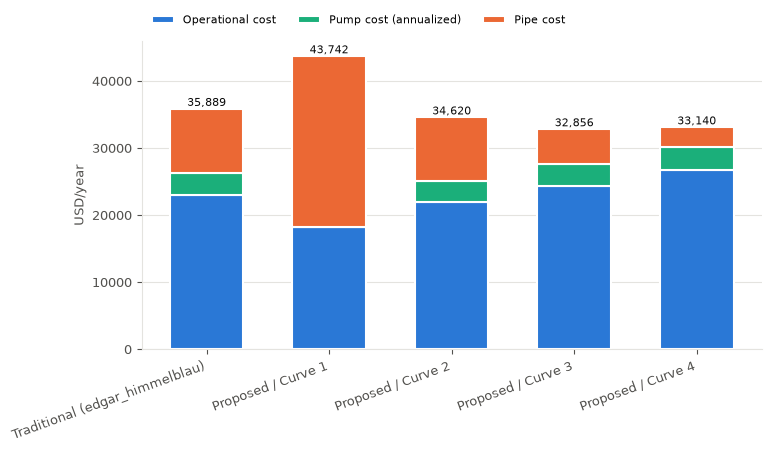

In [10]:
ax = plots.plot_cost_comparison(study)

## Nota: ranking com custos totalmente anualizados

Se o investimento em tubos também for anualizado (Eq. 16), a melhor alternativa de revamp passa a
ser **manter a bomba existente (curva 1)**, com 21 676 USD/ano: o menor custo de energia compensa o
maior investimento em tubos (ver `docs/errata.md`):

In [11]:
display(tables.cost_comparison_table(study, basis="annualized"))

,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible
0,Traditional (edgar_himmelblau),Curve 3,27546,22945,3312,9632,True
1,Proposed / Curve 1,Curve 1,21675,18264,0,25478,True
2,Proposed / Curve 2,Curve 2,26397,21917,3209,9494,True
3,Proposed / Curve 3,Curve 3,28359,24352,3312,5192,True
4,Proposed / Curve 4,Curve 4,30591,26788,3409,2943,True


## Verificação: a rede otimizada entrega as vazões especificadas

,Heat exchanger,Design flow (kg/s),Simulated flow (kg/s),Design hot outlet (degC),Simulated hot outlet (degC),Simulated cold outlet (degC)
0,E-101,7.5,7.5,65.0,65.2,44.4
1,E-102,28.7,28.7,80.0,79.3,40.1
2,E-103,35.6,35.6,40.0,40.1,40.0
3,E-104,15.6,15.6,41.0,41.1,40.0
4,E-105A/B,6.2,6.2,41.0,40.6,40.2
5,E-106,15.6,15.6,41.0,41.1,40.0
6,Total,109.2,109.2,NaN,NaN,NaN


balanceada: True


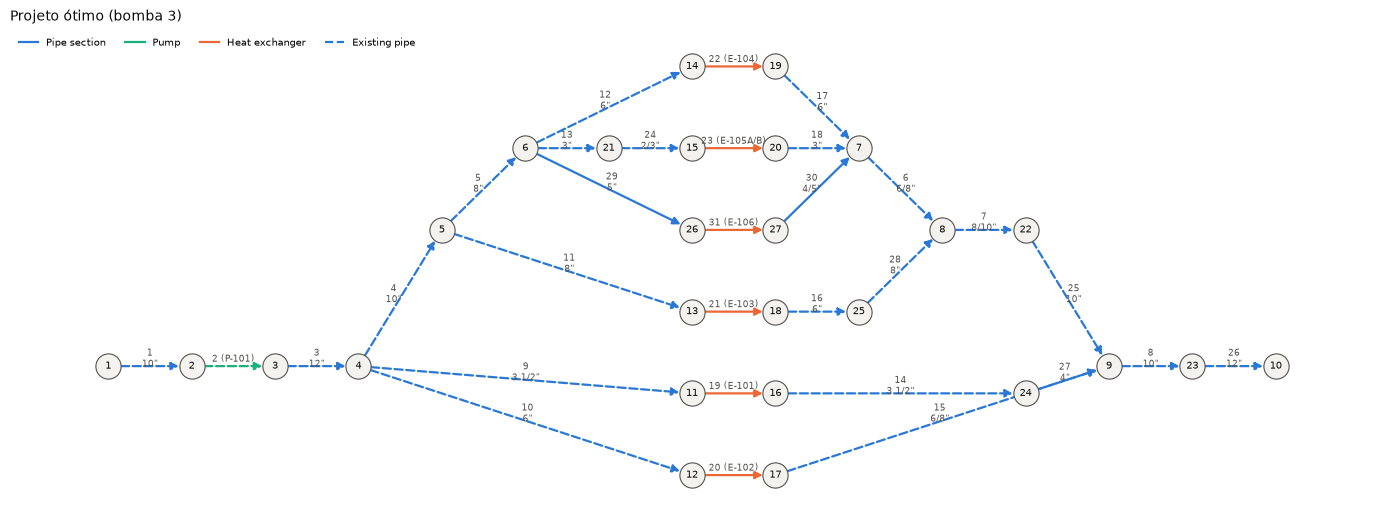

In [12]:
display(tables.network_behaviour_table(study.best))
print("balanceada:", study.best.hydraulically_balanced)
ax = plots.plot_digraph(case, design=study.best.design, title="Projeto ótimo (bomba 3)")